REGRESSION 

 Importing the required libraries


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
# Reading the data from input csv file into a Pandas DataFrame
computers = pd.read_csv("datasets.zip") 
# Printing the first 5 rows
computers.head()

,Units,Minutes
0,1,23
1,2,29
2,3,49
3,4,64
4,4,74


Calculating the mean 


In [8]:
mean_value = computers['Minutes'].mean()
print(mean_value)

97.21428571428571


Plotting the actual time taken for various values of number of faulty units.

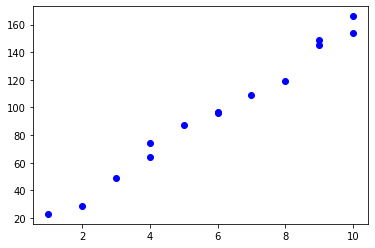

In [9]:
plt.scatter(computers['Units'],computers['Minutes'],color='blue', marker='o')

Plotting the mean

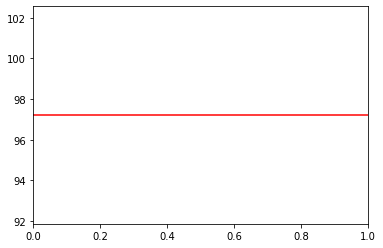

In [10]:
plt.axhline(y=mean_value,c="r")

Adding annotation, xlabel and ylabel.

In [11]:
plt.annotate("Mean repair time",xy = (7.5,mean_value+2))
plt.xlabel("Units")
plt.ylabel("Minutes")

Text(0, 0.5, 'Minutes')

FINAL SCATTER PLOT

Text(0, 0.5, 'Minutes')

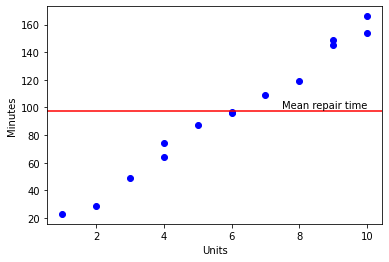

In [12]:
mean_value = computers['Minutes'].mean()
plt.scatter(computers['Units'],computers['Minutes'],color='blue', marker='o')
plt.axhline(y=mean_value,c="r")
plt.annotate("Mean repair time",xy = (7.5,mean_value+2))
plt.xlabel("Units")
plt.ylabel("Minutes")

Best Fit Model

In [13]:
X = computers[['Units']]
y=computers['Minutes']
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X, y)
print("Intercept:", model.intercept_)
print("Coefficients:",model.coef_)

Intercept: 4.161654135338296
Coefficients: [15.50877193]


In [20]:
x = computers.Units
y = computers.Minutes
xiyi = x*y
n = len(computers)
xmean = computers.Units.mean()
ymean = computers.Minutes.mean()
numerator = xiyi.sum() - n*xmean*ymean
denominator = (x**2).sum() - n*(xmean**2)
m = numerator/denominator
c = ymean - (m*xmean)
print('intercept : ',c,' coefficient : ',m)

intercept :  4.161654135338296  coefficient :  15.508771929824569


In [22]:
min_best_fit_model = c + m*computers.Units
computers['min_best_fit_model'] = min_best_fit_model
print(min_best_fit_model)

0      19.670426
1      35.179198
2      50.687970
3      66.196742
4      66.196742
5      81.705514
6      97.214286
7      97.214286
8     112.723058
9     128.231830
10    143.740602
11    143.740602
12    159.249373
13    159.249373
Name: Units, dtype: float64


Validation of best fit model

Text(0.5, 1.0, 'Best fit model line')

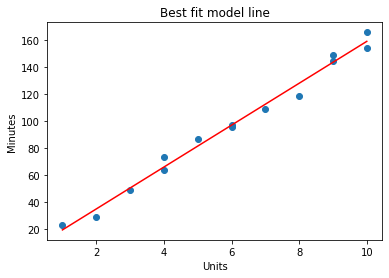

In [23]:
computers[["Units","Minutes","min_best_fit_model"]]
fig,ax = plt.subplots()
ax.scatter(x="Units",y="Minutes",data=computers)
ax.plot(computers.Units,computers.min_best_fit_model,color="red")
ax.set_ylabel("Minutes")
ax.set_xlabel("Units")
ax.set_title("Best fit model line")

Computing the SSE for the best fit model

In [24]:
best_fit_model_obs = pd.DataFrame({"Units":computers.Units,
              "Actual time":computers.Minutes,
              "Predicted time":computers.min_best_fit_model,
              "Error":computers.min_best_fit_model - computers.Minutes})

best_fit_model_obs

,Units,Actual time,Predicted time,Error
0,1,23,19.670426,-3.329574
1,2,29,35.179198,6.179198
2,3,49,50.687970,1.687970
3,4,64,66.196742,2.196742
4,4,74,66.196742,-7.803258
5,5,87,81.705514,-5.294486
6,6,96,97.214286,1.214286
7,6,97,97.214286,0.214286
8,7,109,112.723058,3.723058
9,8,119,128.231830,9.231830


In [25]:
sum(best_fit_model_obs.Error**2)

348.848370927318

Solving Least Squares Regression using Closed Form Linear Equation

In [29]:
X = np.matrix([np.ones(computers.shape[0]),computers["Units"]]).T
y = np.matrix(computers["Minutes"]).reshape(-1,1)
beta = (np.linalg.pinv(X.T*X)*X.T)*y
beta

matrix([[ 4.16165414],
        [15.50877193]])

Coefficient of Determination

In [30]:
SST = sum((computers.Minutes.mean() - computers.Minutes)**2)
SST

27768.357142857145

In [32]:
SSE = sum(best_fit_model_obs.Error**2)
SSE

348.848370927318

In [33]:
SSR = SST - SSE
SSR

27419.508771929828

In [34]:
Rsq = SSR/SST
Rsq

0.9874371980620736

In [35]:
Rsq1 = model.score(computers[["Units"]],y)
Rsq1

/usr/local/lib/python3.7/dist-packages/sklearn/utils/validation.py:598: FutureWarning: np.matrix usage is deprecated in 1.0 and will raise a TypeError in 1.2. Please convert to a numpy array with np.asarray. For more information see: https://numpy.org/doc/stable/reference/generated/numpy.matrix.html
  FutureWarning,


0.9874371980620736

DECISION TREE ON CREDIT RISK DATA SET




Import data set

In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
credit_data = pd.read_csv("creditriskdataset.zip")
credit_data.head()

,over_draft,credit_usage,credit_history,purpose,current_balance,Average_Credit_Balance,employment,location,personal_status,other_parties,...,property_magnitude,cc_age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [38]:
credit_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   over_draft              1000 non-null   object
 1   credit_usage            1000 non-null   int64 
 2   credit_history          1000 non-null   object
 3   purpose                 1000 non-null   object
 4   current_balance         1000 non-null   int64 
 5   Average_Credit_Balance  1000 non-null   object
 6   employment              1000 non-null   object
 7   location                1000 non-null   int64 
 8   personal_status         1000 non-null   object
 9   other_parties           1000 non-null   object
 10  residence_since         1000 non-null   int64 
 11  property_magnitude      1000 non-null   object
 12  cc_age                  1000 non-null   int64 
 13  other_payment_plans     1000 non-null   object
 14  housing                 1000 non-null   object
 15  exist

Setting the predictors and target and Encoding the categorical values

In [40]:
# Selecting the predictor attributes
X = credit_data.columns.drop("class")
# Selecting  the target
y = credit_data['class']
credit_data_encoded = pd.get_dummies(credit_data[X])
print("Total number of predictors after encoding = ", len(credit_data_encoded.columns))
credit_data_encoded.columns

Total number of predictors after encoding =  61


Index(['credit_usage', 'current_balance', 'location', 'residence_since',
       'cc_age', 'existing_credits', 'num_dependents', 'over_draft_0<=X<200',
       'over_draft_<0', 'over_draft_>=200', 'over_draft_no checking',
       'credit_history_all paid',
       'credit_history_critical/other existing credit',
       'credit_history_delayed previously', 'credit_history_existing paid',
       'credit_history_no credits/all paid', 'purpose_business',
       'purpose_domestic appliance', 'purpose_education',
       'purpose_furniture/equipment', 'purpose_new car', 'purpose_other',
       'purpose_radio/tv', 'purpose_repairs', 'purpose_retraining',
       'purpose_used car', 'Average_Credit_Balance_100<=X<500',
       'Average_Credit_Balance_500<=X<1000', 'Average_Credit_Balance_<100',
       'Average_Credit_Balance_>=1000',
       'Average_Credit_Balance_no known savings', 'employment_1<=X<4',
       'employment_4<=X<7', 'employment_<1', 'employment_>=7',
       'employment_unemployed', 'p

Splitting the data into train and test sets

In [41]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(credit_data_encoded, y,test_size=0.15,random_state=100) 
print("Shape of X_train and y_train are:", X_train.shape, "and", y_train.shape, " respectively")
print("Shape of X_test and y_test are:", X_test.shape, "and", y_test.shape, " respectively")

Shape of X_train and y_train are: (850, 61) and (850,)  respectively
Shape of X_test and y_test are: (150, 61) and (150,)  respectively


In [43]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier(random_state = 1)
model.fit(X_train,y_train)
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

Visualizing the decision tree

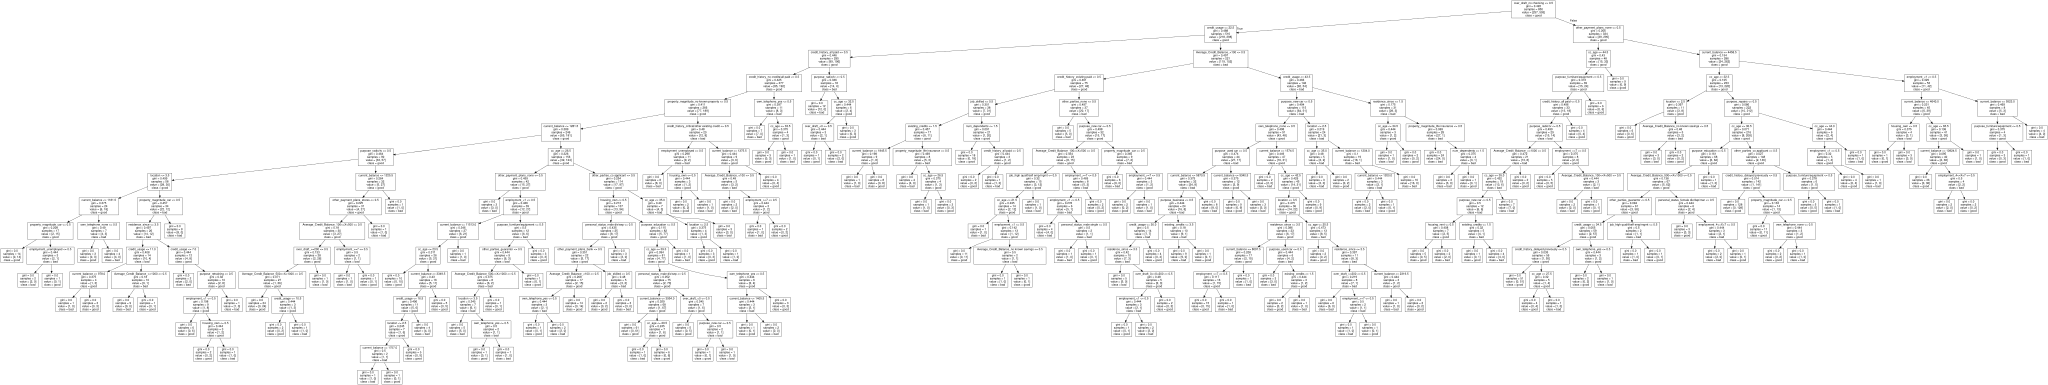

In [44]:
from sklearn.tree import export_graphviz
import graphviz
# Generating the tree
dot_data = export_graphviz(model, out_file=None,
                          feature_names=credit_data_encoded.columns,  
                          class_names=model.classes_,  
                          ) 
graph = graphviz.Source(dot_data) 
graph

Evaluating Performance of a model

In [45]:
train_accuracy = model.score(X_train,y_train)
print("Accuracy of the model on train data = ",train_accuracy)
test_accuracy = model.score(X_test,y_test)
print("Accuracy of the model on test data = ",test_accuracy)

Accuracy of the model on train data =  1.0
Accuracy of the model on test data =  0.6533333333333333


In [46]:
model1 = DecisionTreeClassifier(min_samples_split=10,min_impurity_decrease=0.005)
model1.fit(X_train,y_train)
print("train_accuracy = ", model1.score(X_train,y_train))
print("test_accuracy = ", model1.score(X_test,y_test))

train_accuracy =  0.7635294117647059
test_accuracy =  0.7266666666666667


In [47]:
model2 = DecisionTreeClassifier(min_samples_split=20,min_impurity_decrease=0.1)
# Fitting the model to the training data
model2.fit(X_train,y_train)
# Measuring the accuracy of the model
print("Model2 train accuracy = ", model2.score(X_train,y_train))
print("Model2 test accuracy = ", model2.score(X_test,y_test))

Model2 train accuracy =  0.6976470588235294
Model2 test accuracy =  0.7133333333333334
